# SPHEREx Sky Timeline: las operaciones del código, explicadas paso a paso

Este notebook reproduce, paso a paso y con datos reales, cada operación que hace el código de SPHEREx Sky Timeline (paquete `spherex`): desde pedir la lista de imágenes a IRSA hasta medir el movimiento propio de una estrella, pasando por el formato FITS, las coordenadas, la reproyección, la fotometría y la lectura de Gaia DR3 desde el CDN de la ESA.

Cada sección indica el módulo de `spherex` que implementa lo mismo. El código de este notebook es deliberadamente directo (sin optimizar) para que se pueda comparar línea a línea con el del paquete, y cuando existe una implementación de referencia (astropy, photutils, hpgeom) se compara con ella.

Los métodos siguen los tutoriales de IRSA para SPHEREx y WISE (`spherex_intro`, `spherex_cutouts`, `spherex_psf`, la herramienta de descubrimiento de fuentes y los de catálogos de WISE). Los protocolos y la arquitectura están en [`protocolos-y-datos.md`](protocolos-y-datos.md).

**Cómo ejecutarlo.** Funciona en el entorno de los tutoriales de IRSA (numpy, astropy, matplotlib; photutils y hpgeom son opcionales). Si el proxy del proyecto está en marcha (`serve-web`, puerto 8080) se usa para los recortes y la caché de Gaia, lo que lo hace mucho más rápido; si no, se va directamente a IRSA y al CDN de la ESA. Las secciones que dependen de la red tienen alternativa local cuando el servicio no responde.

| Sección | Operación | Módulo |
|---|---|---|
| 1 | Lista de imágenes (SIA), exposiciones y temporadas | `spherex/irsa/client.py`, `spherex/sky/real.py` |
| 2 | Recortes y formato FITS; quitar la PSF | `spherex/irsa/client.py`, `spherex/fits.py` |
| 3 | Coordenadas celestes TAN-SIP | `spherex/wcs.py` |
| 4 | Longitud de onda por píxel (WAVE-TAB) | `spherex/wcs.py` |
| 5 | Banderas | `spherex/sky/field.py` |
| 6 | Reproyección a una rejilla con norte arriba | `spherex/sky/real.py`, `spherex/sky/grid.py` |
| 7 | Estadística robusta y estiramiento de la imagen | `spherex/sky/field.py`, `spherex/engine/compose.py` |
| 8 | Varias épocas: diferencia y suma | `spherex/engine/compose.py`, `spherex/sky/background.py` |
| 9 | Fotometría de apertura y espectro | `spherex/sky/phot.py` |
| 10 | Centroide, seguimiento y movimiento propio | `spherex/sky/phot.py` |
| 11 | Gaia DR3: HEALPix, CDN, rangos HTTP y teselas | `spherex/gaia` |
| 12 | CatWISE2020 y fusión de catálogos | `spherex/irsa/client.py` |
| 13 | La simulación | `spherex/sky/field.py`, `source.py` |
| 14 | Caché y claves | `spherex/irsa/cache.py`, `spherex/proxy.py` |

In [1]:
import csv, gzip, hashlib, io, json, math, re, struct, time, zlib
import urllib.parse, urllib.request
import xml.etree.ElementTree as ET
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import warnings

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
import astropy.units as u

warnings.simplefilter('ignore')
import logging
logging.getLogger('astropy').setLevel(logging.ERROR)

ROOT = Path('..').resolve()                      # raíz del repositorio (este notebook está en docs/)
FIXTURE = ROOT / 'tests/data/barnard_d6.fits'
PROXY = 'http://localhost:8080'                  # serve-web
IRSA = 'https://irsa.ipac.caltech.edu'
PIX = 6.15                                       # segundos de arco por píxel de SPHEREx
DEG = math.pi / 180

def http_get(url, timeout=120, headers=None):
    req = urllib.request.Request(url, headers=headers or {'User-Agent': 'spherex-sky-timeline-notebook'})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return r.read()

def proxy_available():
    try:
        return json.loads(http_get(PROXY + '/api/health', timeout=3)).get('ok', False)
    except Exception:
        return False

USE_PROXY = proxy_available()
print('Proxy del proyecto disponible:', USE_PROXY)
plt.rcParams.update({'figure.dpi': 100, 'image.origin': 'upper'})

Proxy del proyecto disponible: True


## 1. Lista de imágenes: SIA, exposiciones y temporadas

*Código: `spherex/irsa/client.py` (`visits_sia`, `votable_columns`, `visits_from_rows`), `spherex/sky/real.py` (`new_real_field`).*

El protocolo IVOA **SIA v2** responde qué imágenes contienen una posición. Se piden las colecciones de SPHEREx DR1 y QR3 (como en el tutorial `spherex_intro`) y la respuesta es una VOTable: XML con una tabla en formato `TABLEDATA`. De ella solo hacen falta dos columnas: `access_url` y `t_min` (MJD).

El centro se redondea a 0.0005° (1.8″), igual que hace el motor, para que las claves de caché no cambien cada pocas horas con el movimiento de las estrellas rápidas (sección 14).

In [2]:
def round_pos(ra, dec):
    return round(ra * 2000) / 2000, round(dec * 2000) / 2000

# Estrella de Barnard (posición actual aproximada).
RA, DEC = round_pos(269.446074, 4.770708)
FOV = 6.0  # minutos de arco

def votable_columns(xml_bytes, names):
    root = ET.fromstring(xml_bytes)
    ns = {'v': root.tag.split('}')[0].strip('{')}
    table = root.findall('.//v:TABLE', ns)[-1]          # la última tabla tiene los resultados
    fields = [f.get('name') for f in table.findall('v:FIELD', ns)]
    idx = [fields.index(n) for n in names]
    rows = []
    for tr in table.findall('.//v:TR', ns):
        tds = [td.text or '' for td in tr.findall('v:TD', ns)]
        rows.append([tds[i] for i in idx])
    return rows

def sia_rows(ra, dec):
    q = urllib.parse.urlencode([('COLLECTION', 'spherex_dr1'), ('COLLECTION', 'spherex_qr3'),
                                ('POS', f'circle {ra} {dec} 0.0003'), ('RESPONSEFORMAT', 'VOTABLE')])
    return votable_columns(http_get(f'{IRSA}/SIA?{q}'), ['access_url', 't_min'])

t0 = time.time()
try:
    rows = sia_rows(RA, DEC)
    print(f'SIA: {len(rows)} filas en {time.time() - t0:.1f} s')
except Exception as e:
    # Alternativa: la misma lista a través del proxy (que usa SIA o TAP y cachea).
    print('SIA no respondió:', e)
    data = json.loads(http_get(f'{PROXY}/api/visits?ra={RA}&dec={DEC}'))
    rows = [[v['path'], str(v['mjd'])] for v in data['visits']]
    print(f'proxy: {len(rows)} filas')
rows[:2]

SIA no respondió: HTTP Error 502: Proxy Error
proxy: 358 filas


[['ibe/data/spherex/dr1/level2/2025W33_2C/l2b-v27-2026-228/3/level2_2025W33_2C_0321_1D3_spx_l2b-v27-2026-228.fits',
  '60902.864715'],
 ['ibe/data/spherex/dr1/level2/2025W33_2C/l2b-v27-2026-228/6/level2_2025W33_2C_0321_1D6_spx_l2b-v27-2026-228.fits',
  '60902.864715']]

Una misma exposición y detector puede aparecer más de una vez (reprocesada con `_retry`, o en QR3 y en DR1). El nombre del archivo `level2_<exposición>D<detector>_spx…` da la clave; si se repite, se prefiere DR1.

In [3]:
FILE_RE = re.compile(r'level2_(\w+?_\d+_\d+)D(\d)_spx')

def visits_from_rows(rows):
    best = {}
    for uri, mjd in rows:
        m = FILE_RE.search(uri)
        if not m:
            continue
        path = uri[uri.index('ibe/data/spherex/'):] if 'ibe/data/spherex/' in uri else uri.lstrip('/')
        release = path.split('/')[3]                       # ibe/data/spherex/<release>/...
        v = dict(path=path, mjd=float(mjd), detector=int(m[2]), exposure=m[1], release=release)
        key = (v['exposure'], v['detector'])
        rank = ('1' if release.startswith('dr') else '0') + path
        if key not in best or rank > best[key][0]:
            best[key] = (rank, v)
    return sorted((v for _, v in best.values()), key=lambda v: (v['mjd'], v['detector']))

visits = visits_from_rows(rows)
print(len(visits), 'imágenes únicas; por detector:', dict(sorted(Counter(v['detector'] for v in visits).items())))
print('Entregas:', Counter(v['release'] for v in visits))

358 imágenes únicas; por detector: {1: 60, 2: 61, 3: 59, 4: 59, 5: 61, 6: 58}
Entregas: Counter({'dr1': 239, 'qr3': 119})


**Exposiciones y parejas de detectores.** SPHEREx tiene dos planos focales que ven el mismo cielo a través de un divisor dicroico; en cada exposición un punto cae en una pareja de detectores: D1+D4, D2+D5 o D3+D6. El motor llama *visita* a una exposición; los otros cuatro canales no tienen imagen en ella.

**Temporadas.** Las visitas se agrupan por pasadas del survey (cada ~6 meses): una separación de más de 40 días empieza una temporada nueva.

Parejas de detectores por exposición: Counter({(2, 5): 60, (1, 4): 59, (3, 6): 58, (3,): 1, (1,): 1, (5,): 1, (2,): 1})
181 exposiciones en 3 temporadas


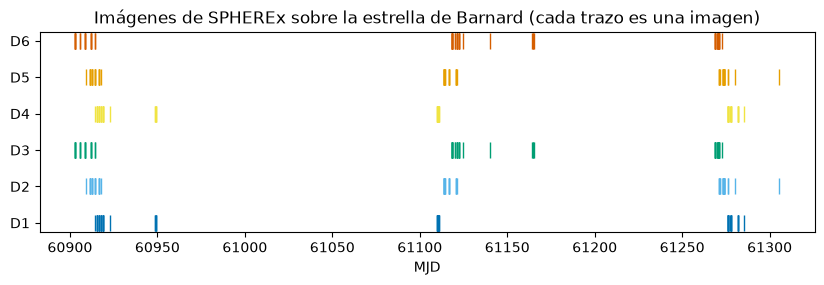

In [4]:
exposures = {}
for v in visits:
    exposures.setdefault(v['exposure'], []).append(v)
exp_list = sorted(exposures.values(), key=lambda e: min(x['mjd'] for x in e))
print('Parejas de detectores por exposición:', Counter(tuple(sorted(x['detector'] for x in e)) for e in exp_list))

SEASON_GAP = 40
season, prev = 0, None
for e in exp_list:
    mjd = min(x['mjd'] for x in e)
    if prev is not None and mjd - prev > SEASON_GAP:
        season += 1
    for x in e:
        x['season'] = season
    prev = mjd
print(len(exp_list), 'exposiciones en', season + 1, 'temporadas')

fig, ax = plt.subplots(figsize=(10, 2.6))
colors = ['#0072B2', '#56B4E9', '#009E73', '#F0E442', '#E69F00', '#D55E00']
for v in visits:
    ax.plot(v['mjd'], v['detector'], '|', ms=12, color=colors[v['detector'] - 1])
ax.set_yticks(range(1, 7), [f'D{d}' for d in range(1, 7)])
ax.set_xlabel('MJD'); ax.set_title('Imágenes de SPHEREx sobre la estrella de Barnard (cada trazo es una imagen)')
plt.show()

## 2. Recortes y formato FITS

*Código: `spherex/irsa/client.py` (`cutout`), `spherex/fits.py` (`parse`, `join`), `spherex/engine/app.py` (`cutout_size`).*

Cada imagen se pide recortada añadiendo `?center=<ra>,<dec>d&size=<grados>` a su URL (servicio de recortes de IRSA, tutorial `spherex_cutouts`). El recorte llega en la orientación del detector, rotado respecto al norte, así que su lado debe cubrir las esquinas del campo norte-arriba en cualquier ángulo: `lado = campo × √2 × 1.02`.

In [5]:
def cutout_size(fov_arcmin):
    return fov_arcmin / 60 * math.sqrt(2) * 1.02

SIZE = round(cutout_size(FOV), 5)
d6 = [v for v in visits if v['detector'] == 6]
example = d6[0]
cutout_url = f"{IRSA}/{example['path']}?center={RA:.6f},{DEC:.6f}d&size={SIZE:.5f}"
print('Lado del recorte:', SIZE, 'grados =', round(SIZE * 3600 / PIX), 'píxeles')
print(cutout_url)

Lado del recorte: 0.14425 grados = 84 píxeles
https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/level2/2025W33_2C/l2b-v27-2026-228/6/level2_2025W33_2C_0321_1D6_spx_l2b-v27-2026-228.fits?center=269.446000,4.770500d&size=0.14425


Un FITS está hecho de bloques de 2880 bytes. Cada HDU tiene una cabecera de tarjetas de 80 caracteres ASCII (`CLAVE   = valor / comentario`) que termina en `END`, rellena hasta el bloque, seguida de los datos (big-endian) también rellenos. El tamaño de los datos es `|BITPIX|/8 × NAXIS1 × … × NAXISn`, más `PCOUNT`, por `GCOUNT`.

Esto es lo que hace `spherex/fits.py`: leer las cabeceras, saltar los datos y poder volver a escribir las HDU que interesan byte a byte. Así el proxy quita la extensión `EPSF`.

In [6]:
BLOCK = 2880

def parse_hdus(data):
    hdus, off = [], 0
    while off < len(data):
        start, cards = off, []
        while True:
            block = data[off:off + BLOCK]; off += BLOCK
            cs = [block[i:i + 80].decode('ascii') for i in range(0, BLOCK, 80)]
            cards += cs
            if any(c.rstrip() == 'END' for c in cs):
                break
        hdr = {}
        for c in cards:
            if c[8:10] == '= ':
                val = c[10:].strip()
                if val.startswith("'"):
                    val = val[1:val.index("'", 1)].strip()
                else:
                    val = val.split('/')[0].strip()
                hdr.setdefault(c[:8].strip(), val)
        naxis, size = int(hdr.get('NAXIS', 0)), 0
        if naxis:
            size = abs(int(hdr['BITPIX'])) // 8
            for i in range(1, naxis + 1):
                size *= int(hdr[f'NAXIS{i}'])
            size = int(hdr.get('GCOUNT', 1)) * (size + int(hdr.get('PCOUNT', 0)))
        padded = -(-size // BLOCK) * BLOCK
        hdus.append({'name': hdr.get('EXTNAME', 'PRIMARY'), 'header': hdr, 'raw': data[start:off + padded]})
        off += padded
    return hdus

try:
    t0 = time.time()
    raw = http_get(cutout_url, timeout=180)
    print(f'Recorte original: {len(raw) / 1e6:.2f} MB en {time.time() - t0:.1f} s')
except Exception as e:
    print('IRSA no respondió, se usa el recorte del repositorio (ya sin EPSF):', e)
    raw = FIXTURE.read_bytes()

hdus = parse_hdus(raw)
for h in hdus:
    print(f"{h['name']:9s} {len(h['raw']) / 1e3:9.1f} kB  BITPIX={h['header'].get('BITPIX'):>4}  NAXIS={h['header'].get('NAXIS')}")

stripped = b''.join(h['raw'] for h in hdus if h['name'] != 'EPSF')
print(f'\nSin EPSF: {len(stripped) / 1e3:.0f} kB ({100 * (1 - len(stripped) / len(raw)):.0f} % menos)')

# astropy lee el resultado sin problemas: la operación preserva el formato.
with fits.open(io.BytesIO(stripped)) as h:
    h.info()

IRSA no respondió, se usa el recorte del repositorio (ya sin EPSF): HTTP Error 503: Service Unavailable
PRIMARY         2.9 kB  BITPIX=   8  NAXIS=0
IMAGE          37.4 kB  BITPIX= -32  NAXIS=2
FLAGS          31.7 kB  BITPIX=  32  NAXIS=2
VARIANCE       25.9 kB  BITPIX= -32  NAXIS=2
ZODI           25.9 kB  BITPIX= -32  NAXIS=2
WCS-WAVE        5.8 kB  BITPIX=   8  NAXIS=2

Sin EPSF: 130 kB (0 % menos)
Filename: <class '_io.BytesIO'>
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU       275   (58, 59)   float32   
  2  FLAGS         1 ImageHDU       185   (58, 59)   int32   
  3  VARIANCE      1 ImageHDU       119   (58, 59)   float32   
  4  ZODI          1 ImageHDU       122   (58, 59)   float32   
  5  WCS-WAVE      1 BinTableHDU     22   1R x 3C   [9J, 9J, 162E]   


A partir de aquí se usa el recorte de Barnard en el detector 6 que el repositorio guarda como dato de prueba (`tests/data/barnard_d6.fits`), el mismo con el que se validan las pruebas.

In [7]:
hdul = fits.open(FIXTURE)
img_hdr = hdul['IMAGE'].header
IMG = hdul['IMAGE'].data.astype(float)
ZODI = hdul['ZODI'].data.astype(float)
VAR = hdul['VARIANCE'].data.astype(float)
FLAGS = hdul['FLAGS'].data.astype(np.int64)
print('Tamaño:', IMG.shape, '| unidad:', img_hdr['BUNIT'], '| detector:', img_hdr['DETECTOR'], '| MJD:', img_hdr['MJD-AVG'])
print('PSF FWHM mediana:', round(img_hdr['PSF_FWHM'], 2), 'arcsec')

Tamaño: (59, 58) | unidad: MJy / sr | detector: 6 | MJD: 60902.865380738
PSF FWHM mediana: 9.04 arcsec


## 3. Coordenadas celestes: proyección TAN con distorsión SIP

*Código: `spherex/wcs.py` (`Celestial`, `pixel_to_sky`, `sky_to_pixel`).*

La cabecera describe cómo pasar de píxel a cielo (`spherex_intro`, sección 8a):

1. **Píxel → desplazamiento**: con píxeles en base 1, `u = x − CRPIX1`, `v = y − CRPIX2`.
2. **Distorsión SIP**: `u' = u + Σ A_pq u^p v^q`, `v' = v + Σ B_pq u^p v^q`.
3. **Plano tangente**: `(ξ, η) = CD · (u', v')` en grados, con `CD = diag(CDELT) · PC`.
4. **Proyección gnomónica inversa** respecto al punto tangente `(CRVAL1, CRVAL2)`.

Para ir del cielo al píxel se proyecta, se invierte `CD` y se usan los polinomios inversos `AP`, `BP` que trae la cabecera. Como solo aproximan la inversa, el resultado se pule con tres iteraciones contra los polinomios directos.

Las coordenadas de píxel son en base 0 (el centro del primer píxel es 0), como en astropy.

In [8]:
class Celestial:
    def __init__(self, h):
        self.crpix = np.array([h['CRPIX1'], h['CRPIX2']], float)
        self.crval = np.array([h['CRVAL1'], h['CRVAL2']], float)
        if 'CD1_1' in h:
            cd = [[h['CD1_1'], h.get('CD1_2', 0)], [h.get('CD2_1', 0), h['CD2_2']]]
        else:
            d1, d2 = h.get('CDELT1', 1), h.get('CDELT2', 1)
            cd = [[d1 * h.get('PC1_1', 1), d1 * h.get('PC1_2', 0)], [d2 * h.get('PC2_1', 0), d2 * h.get('PC2_2', 1)]]
        self.cd = np.array(cd, float)
        self.inv = np.linalg.inv(self.cd)
        self.A, self.B, self.AP, self.BP = (self.poly(h, n) for n in ('A', 'B', 'AP', 'BP'))

    @staticmethod
    def poly(h, name):
        order = h.get(f'{name}_ORDER', 0)
        return {(i, j): h[f'{name}_{i}_{j}'] for i in range(order + 1) for j in range(order + 1 - i) if f'{name}_{i}_{j}' in h}

    @staticmethod
    def ev(p, u, v):
        return sum(c * u**i * v**j for (i, j), c in p.items()) if p else 0 * u

    def pixel_to_sky(self, x, y):
        u, v = x + 1 - self.crpix[0], y + 1 - self.crpix[1]
        u, v = u + self.ev(self.A, u, v), v + self.ev(self.B, u, v)
        xi = (self.cd[0, 0] * u + self.cd[0, 1] * v) * DEG
        eta = (self.cd[1, 0] * u + self.cd[1, 1] * v) * DEG
        a0, d0 = self.crval * DEG
        den = np.cos(d0) - eta * np.sin(d0)
        ra = a0 + np.arctan2(xi, den)
        dec = np.arctan2(np.sin(d0) + eta * np.cos(d0), np.hypot(xi, den))
        return np.mod(ra / DEG, 360), dec / DEG

    def sky_to_pixel(self, ra, dec):
        a, d = np.asarray(ra) * DEG, np.asarray(dec) * DEG
        a0, d0 = self.crval * DEG
        cosc = np.sin(d0) * np.sin(d) + np.cos(d0) * np.cos(d) * np.cos(a - a0)
        xi = np.cos(d) * np.sin(a - a0) / cosc / DEG
        eta = (np.cos(d0) * np.sin(d) - np.sin(d0) * np.cos(d) * np.cos(a - a0)) / cosc / DEG
        up = self.inv[0, 0] * xi + self.inv[0, 1] * eta
        vp = self.inv[1, 0] * xi + self.inv[1, 1] * eta
        u, v = up + self.ev(self.AP, up, vp), vp + self.ev(self.BP, up, vp)
        for _ in range(3):                               # pulir contra los polinomios directos
            fu, fv = u + self.ev(self.A, u, v), v + self.ev(self.B, u, v)
            u, v = u - (fu - up), v - (fv - vp)
        return u + self.crpix[0] - 1, v + self.crpix[1] - 1

cel = Celestial(img_hdr)
ref = WCS(img_hdr)

ys, xs = np.mgrid[0:IMG.shape[0]:7, 0:IMG.shape[1]:7].astype(float)
ra_go, dec_go = cel.pixel_to_sky(xs, ys)
c_ref = ref.pixel_to_world(xs, ys)
err_arcsec = np.hypot((ra_go - c_ref.ra.deg) * np.cos(dec_go * DEG), dec_go - c_ref.dec.deg) * 3600
print(f'píxel → cielo: diferencia máxima con astropy {err_arcsec.max():.2e} arcsec')

x_go, y_go = cel.sky_to_pixel(c_ref.ra.deg, c_ref.dec.deg)
print(f'cielo → píxel: diferencia máxima con astropy {np.hypot(x_go - xs, y_go - ys).max():.2e} píxeles')

rot = math.degrees(math.atan2(cel.cd[1, 0], cel.cd[0, 0]))
print(f'El recorte está rotado ~{rot:.0f}° respecto al eje RA (por eso se reproyecta).')

píxel → cielo: diferencia máxima con astropy 2.12e-10 arcsec
cielo → píxel: diferencia máxima con astropy 1.74e-10 píxeles
El recorte está rotado ~-5° respecto al eje RA (por eso se reproyecta).


## 4. Longitud de onda por píxel: WAVE-TAB

*Código: `spherex/wcs.py` (`Wave`, `at`, `_cell`).*

SPHEREx usa filtros lineales variables: cada fila del detector ve otra longitud de onda. La cabecera incluye un WCS alternativo `W` de tipo `WAVE-TAB`, y la extensión `WCS-WAVE` trae una rejilla 9×9 de puntos de control sobre el detector completo (2040×2040) con `(λ, ancho de banda)` en cada uno. La longitud de onda de un píxel se obtiene así (`spherex_intro`, secciones 8b y 13):

1. **Del recorte al detector**: con píxeles en base 1, `p = (x − CRPIX1W)·CDELT1W + CRVAL1W`, lo mismo en y. Es el desplazamiento del recorte dentro del detector, el mismo que usa `spherex_psf` en su sección 4.3.
2. **Interpolación bilineal** en la rejilla de control, que no es uniforme.

Según el tutorial, la distorsión SIP **no** se aplica a este WCS.

`VALUES` tiene `TDIM = (2, 9, 9)`: en orden FITS el índice más rápido es (λ, ancho), luego x y luego y. En memoria plana: `values[2·(i + 9·j) + k]`, que es lo que lee `spherex/wcs.py`.

Puntos de control X: [   1  256  511  766 1021 1275 1530 1785 2040]
Forma de VALUES en astropy: (9, 9, 2) → [j (y), i (x), k (λ o ancho)]
λ: diferencia máxima con astropy 1.8e-15 µm
ancho de banda: diferencia máxima 1.4e-17 µm


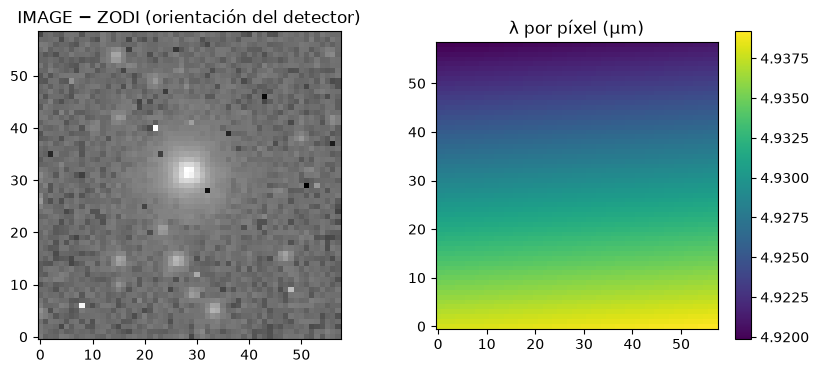

In [9]:
tab = hdul['WCS-WAVE'].data
CX, CY, VALUES = tab['X'][0].astype(float), tab['Y'][0].astype(float), tab['VALUES'][0].astype(float)
print('Puntos de control X:', CX.astype(int))
print('Forma de VALUES en astropy:', VALUES.shape, '→ [j (y), i (x), k (λ o ancho)]')

def cell(ctrl, p):
    i = np.clip(np.searchsorted(ctrl, p) - 1, 0, len(ctrl) - 2)
    f = np.clip((p - ctrl[i]) / (ctrl[i + 1] - ctrl[i]), 0, 1)
    return i, f

def wave_table(h):
    t = h['WCS-WAVE'].data
    return t['X'][0].astype(float), t['Y'][0].astype(float), t['VALUES'][0].astype(float)

def wave_at(x, y, hdr, table):
    cx, cy, values = table
    px = (np.asarray(x) + 1 - hdr['CRPIX1W']) * hdr['CDELT1W'] + hdr['CRVAL1W']
    py = (np.asarray(y) + 1 - hdr['CRPIX2W']) * hdr['CDELT2W'] + hdr['CRVAL2W']
    i, fx = cell(cx, px)
    j, fy = cell(cy, py)
    out = []
    for k in range(2):
        out.append((1 - fx) * (1 - fy) * values[j, i, k] + fx * (1 - fy) * values[j, i + 1, k]
                   + (1 - fx) * fy * values[j + 1, i, k] + fx * fy * values[j + 1, i + 1, k])
    return out

TABLE = wave_table(hdul)

swcs = WCS(img_hdr, fobj=hdul, key='W')
swcs.sip = None                                         # como indica el tutorial
lam_go, bw_go = wave_at(xs, ys, img_hdr, TABLE)
lam_ref, bw_ref = swcs.pixel_to_world(xs, ys)
print(f'λ: diferencia máxima con astropy {np.abs(lam_go - lam_ref.to(u.um).value).max():.1e} µm')
print(f'ancho de banda: diferencia máxima {np.abs(bw_go - bw_ref.to(u.um).value).max():.1e} µm')

yy, xx = np.mgrid[0:IMG.shape[0], 0:IMG.shape[1]]
lam_map, _ = wave_at(xx, yy, img_hdr, TABLE)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(np.arcsinh((IMG - ZODI) / 0.05), origin='lower', cmap='gray'); ax[0].set_title('IMAGE − ZODI (orientación del detector)')
im = ax[1].imshow(lam_map, origin='lower', cmap='viridis'); ax[1].set_title('λ por píxel (µm)')
plt.colorbar(im, ax=ax[1]); plt.show()

## 5. Banderas

*Código: `spherex/sky/field.py` (`FLAG_BITS`, `BAD_MASK`, `flag_names`).*

La extensión `FLAGS` es una máscara de bits; la cabecera nombra cada bit (`MSKNnnnn`) y lo describe (`MSKDnnnn`), como muestra el tutorial (sección 9). Para decidir qué píxeles no sirven para medir se usa la misma lista que la herramienta de descubrimiento de fuentes (su aviso `CONTAINS_BAD_PIXEL`). `SOURCE`, que marca casi todos los píxeles que caen sobre fuentes conocidas, es informativo y **no** cuenta como malo, y tampoco `FULLSAMPLE`, `PHANMISS` ni `OUTLIER`.

bit  0  TRANSIENT    malo     35 píxeles  Transient detected during SUR
bit  1  OVERFLOW     malo      2 píxeles  Overflow detected during SUR
bit  2  SUR_ERROR    malo     19 píxeles  Error in onboard processing
bit  6  NONFUNC      malo     13 píxeles  Permanently unusable
bit  7  DICHROIC     malo      0 píxeles  Low efficiency due to dichroic
bit  9  MISSING_DATA malo      0 píxeles  Onboard data lost
bit 10  HOT          malo      0 píxeles  Hot pixel
bit 11  COLD         malo      3 píxeles  Anomalously low signal
bit 12  FULLSAMPLE             0 píxeles  Pixel full sample history is available
bit 14  PHANMISS               0 píxeles  Phantom correction was not applied
bit 15  NONLINEAR    malo      0 píxeles  Nonlinearity correction cannot be applied reliably
bit 17  PERSIST      malo      1 píxeles  Persistent charge above threshold
bit 19  OUTLIER                1 píxeles  Pixel flagged by Detect Outliers
bit 20  CROSSTALK    malo      0 píxeles  Pixel affected by crosstalk.
b

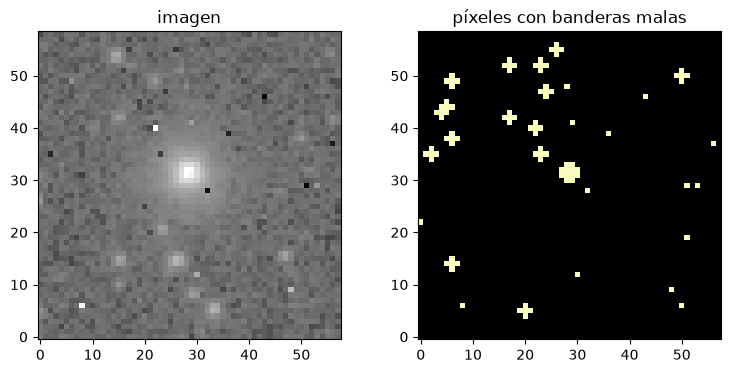

In [10]:
fh = hdul['FLAGS'].header
BITS = {fh[k]: int(k[4:]) for k in fh if k.startswith('MSKN')}
BAD_NAMES = ['TRANSIENT', 'OVERFLOW', 'SUR_ERROR', 'NONFUNC', 'DICHROIC', 'MISSING_DATA', 'HOT', 'COLD',
             'NONLINEAR', 'CROSSTALK', 'GHOST', 'GHOST_FPA', 'GHOST_EXT', 'STREAK', 'PERSIST', 'BLOOM', 'SNOWBALL', 'HALO']
BAD_MASK = sum(1 << BITS[n] for n in BAD_NAMES if n in BITS)
NONLINEAR, MISSING = 1 << BITS['NONLINEAR'], 1 << BITS['MISSING_DATA']

for name, bit in sorted(BITS.items(), key=lambda kv: kv[1]):
    n = int(((FLAGS >> bit) & 1).sum())
    print(f"bit {bit:2d}  {name:12s} {'malo' if name in BAD_NAMES else '    '}  {n:5d} píxeles  {fh.get(f'MSKD{bit:04d}', '')}")

bad = (FLAGS & BAD_MASK) != 0
print(f'\nPíxeles malos: {bad.mean() * 100:.1f} %')
j, i = np.unravel_index(np.nanargmax(IMG), IMG.shape)
core = FLAGS[j - 1:j + 2, i - 1:i + 2]
print('Banderas en el núcleo de Barnard (3×3):', sorted({n for n, b in BITS.items() if (core >> b & 1).any() and n in BAD_NAMES}))

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(np.arcsinh((IMG - ZODI) / 0.05), origin='lower', cmap='gray'); ax[0].set_title('imagen')
ax[1].imshow(bad, origin='lower', cmap='magma'); ax[1].set_title('píxeles con banderas malas')
plt.show()

## 6. Reproyección a una rejilla con norte arriba

*Código: `spherex/sky/grid.py` (`WCS.to_pixel`, `to_sky`), `spherex/sky/real.py` (`load_cutout`, `bilinear`).*

Para comparar imágenes de fechas distintas, todas se llevan a la misma rejilla: proyección gnomónica centrada en el campo, píxeles de 6.15″, norte arriba y este a la izquierda. En esta rejilla el píxel `i` cubre `[i, i+1)` y el centro del campo está en `n/2`.

Para cada píxel de la rejilla:

1. Se calcula su posición en el cielo (centro del píxel, `i + 0.5`).
2. Se busca esa posición en el recorte con `sky_to_pixel` (sección 3).
3. Se interpola bilinealmente `IMAGE − ZODI`. Se resta el modelo de luz zodiacal para que el fondo coincida entre visitas.
4. Se interpola también `VARIANCE`.
5. Las banderas se toman del píxel más cercano.
6. Lo que cae fuera del recorte se marca `MISSING_DATA`.

Rejilla: 59 × 59 píxeles; λ en el centro del campo: 4.929 µm


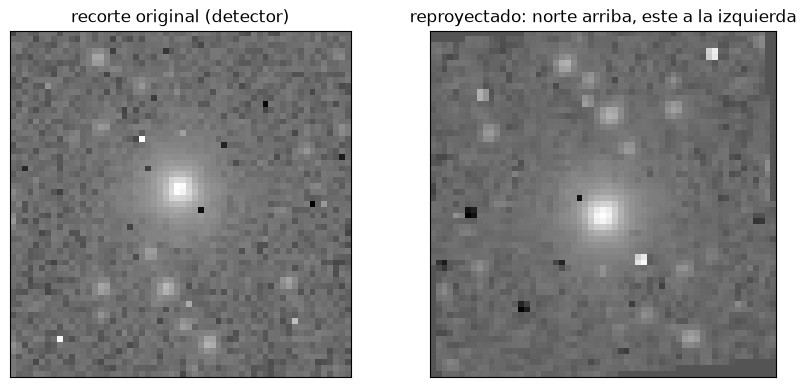

In [11]:
class Grid:
    # Rejilla del campo: gnomónica, norte arriba, este a la izquierda.
    def __init__(self, ra, dec, fov_arcmin):
        self.ra, self.dec = ra, dec
        self.n = max(16, int(round(fov_arcmin * 60 / PIX)))
        self.c = self.n / 2
        self.s = PIX / 3600 * DEG

    def to_pixel(self, ra, dec):
        a, d = np.asarray(ra) * DEG, np.asarray(dec) * DEG
        a0, d0 = self.ra * DEG, self.dec * DEG
        cosc = np.sin(d0) * np.sin(d) + np.cos(d0) * np.cos(d) * np.cos(a - a0)
        xi = np.cos(d) * np.sin(a - a0) / cosc
        eta = (np.cos(d0) * np.sin(d) - np.sin(d0) * np.cos(d) * np.cos(a - a0)) / cosc
        return self.c - xi / self.s, self.c - eta / self.s

    def to_sky(self, x, y):
        xi, eta = -(np.asarray(x, float) - self.c) * self.s, -(np.asarray(y, float) - self.c) * self.s
        a0, d0 = self.ra * DEG, self.dec * DEG
        rho = np.hypot(xi, eta)
        rho = np.where(rho == 0, 1e-300, rho)
        c = np.arctan(rho)
        dec = np.arcsin(np.cos(c) * np.sin(d0) + eta * np.sin(c) * np.cos(d0) / rho)
        ra = a0 + np.arctan2(xi * np.sin(c), rho * np.cos(d0) * np.cos(c) - eta * np.sin(d0) * np.sin(c))
        return np.mod(ra / DEG, 360), dec / DEG

def bilinear(a, b, x, y):
    h, w = a.shape
    x0, y0 = np.floor(x).astype(int), np.floor(y).astype(int)
    fx, fy = x - x0, y - y0
    s, ws = np.zeros_like(x), np.zeros_like(x)
    for dy in (0, 1):
        for dx in (0, 1):
            xi, yi = x0 + dx, y0 + dy
            ok = (xi >= 0) & (yi >= 0) & (xi < w) & (yi < h)
            v = np.full(x.shape, np.nan)
            v[ok] = a[yi[ok], xi[ok]] - (b[yi[ok], xi[ok]] if b is not None else 0)
            wt = (1 - np.abs(dx - fx)) * (1 - np.abs(dy - fy))
            good = ok & np.isfinite(v)
            s[good] += wt[good] * v[good]
            ws[good] += wt[good]
    return np.where(ws >= 0.25, s / np.where(ws > 0, ws, 1), np.nan)

def reproject(h, grid):
    # Reproyecta un recorte (HDUList) a la rejilla; devuelve un 'frame' como los del motor.
    hdr = h['IMAGE'].header
    cel = Celestial(hdr)
    img, zodi = h['IMAGE'].data.astype(float), h['ZODI'].data.astype(float)
    var, flg = h['VARIANCE'].data.astype(float), h['FLAGS'].data.astype(np.int64)
    jj, ii = np.mgrid[0:grid.n, 0:grid.n]
    ra, dec = grid.to_sky(ii + 0.5, jj + 0.5)
    x, y = cel.sky_to_pixel(ra, dec)
    xi, yi = np.round(x).astype(int), np.round(y).astype(int)
    inside = (xi >= 0) & (yi >= 0) & (xi < img.shape[1]) & (yi < img.shape[0])
    flags = np.full(x.shape, MISSING, np.int64)
    flags[inside] = flg[yi[inside], xi[inside]]
    out = bilinear(img, zodi, x, y)
    flags[~np.isfinite(out)] |= MISSING
    frame = dict(image=np.nan_to_num(out), variance=np.nan_to_num(bilinear(var, None, x, y)), flags=flags,
                 mjd=hdr['MJD-AVG'], detector=hdr['DETECTOR'], header=hdr, wcs=cel, table=wave_table(h))
    # λ en el centro del campo (Frame.lambda_ en el paquete) y en cualquier posición (Frame.lambda_at).
    frame['lambda_at'] = lambda ra, dec: float(wave_at(*cel.sky_to_pixel(ra, dec), hdr, frame['table'])[0])
    frame['lambda'] = frame['lambda_at'](grid.ra, grid.dec)
    return frame

grid = Grid(RA, DEC, FOV)
frame = reproject(hdul, grid)
print('Rejilla:', grid.n, '×', grid.n, 'píxeles; λ en el centro del campo:', round(frame['lambda'], 3), 'µm')

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
ax[0].imshow(np.arcsinh((IMG - ZODI) / 0.05), origin='lower', cmap='gray'); ax[0].set_title('recorte original (detector)')
ax[1].imshow(np.arcsinh(frame['image'] / 0.05), cmap='gray'); ax[1].set_title('reproyectado: norte arriba, este a la izquierda')
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.show()

**Comprobación con la posición de Gaia.** Barnard tiene un movimiento propio de 10.4″/año. Llevando su posición de Gaia DR3 (época J2016.0) a la fecha de la imagen, debe caer donde se ve la estrella.

In [12]:
GAIA_EPOCH = 57388.5   # J2016.0 en MJD
BARNARD = dict(ra=269.44850252544, dec=4.73942005111, pmra=-801.551, pmdec=10362.394, mjd=GAIA_EPOCH)

def position(src, mjd):
    # Movimiento propio lineal (sky.Source.Position); pmra incluye cos(dec), en mas/año.
    yr = (mjd - src['mjd']) / 365.25
    dec = src['dec'] + src['pmdec'] * yr / 3.6e6
    ra = src['ra'] + src['pmra'] * yr / 3.6e6 / math.cos(src['dec'] * DEG)
    return ra, dec

px, py = grid.to_pixel(*position(BARNARD, frame['mjd']))
print(f'Barnard predicho en la rejilla: ({px:.2f}, {py:.2f})')

Barnard predicho en la rejilla: (29.29, 31.48)


## 7. Estadística robusta y estiramiento de la imagen

*Código: `spherex/sky/field.py` (`stats`, `percentile`), `spherex/engine/app.py` (`_init_stretch`), `spherex/engine/compose.py` (`colorize`).*

- **Fondo y ruido**: mediana y MAD × 1.4826 (equivalente a σ para ruido gaussiano) de los píxeles sin banderas malas. Son robustos frente a estrellas y rayos cósmicos.
- **Estiramiento**: se fija una vez por canal con la primera imagen que llega, y no cambia de un fotograma a otro, para que el parpadeo refleje cambios reales y no un reajuste automático. Con `t = asinh((v − mediana)/(2σ))`, el gris es `(t − asinh(−0.75)) / (asinh(alto/(2σ)) − asinh(−0.75))`, recortado a [0, 1]. `alto` es el percentil 99.8 menos la mediana, con un mínimo de 30σ.
- **Diferencia**: gris `0.5 + 0.5·asinh(Δ/(2σ))/asinh(20)`, de modo que el blanco es más brillo y el negro menos.
- **Teñido opcional**: `color·t + (blanco − color)·t⁴`. Lo débil toma el color del canal y lo brillante va a blanco.

fondo 0.1011 MJy/sr, ruido σ 0.0614 MJy/sr, alto 41.82


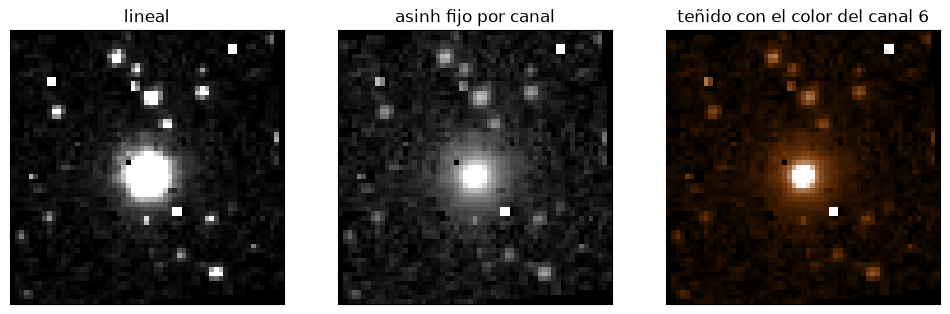

In [13]:
def stats(img, flags):
    v = img[(flags & BAD_MASK) == 0]
    med = np.median(v)
    return med, max(1.4826 * np.median(np.abs(v - med)), 1e-6)

def percentile(img, flags, p):
    v = np.sort(img[(flags & BAD_MASK) == 0])
    return v[min(len(v) - 1, int(p * len(v)))]

med, sig = stats(frame['image'], frame['flags'])
high = max(percentile(frame['image'], frame['flags'], 0.998) - med, 30 * sig)
print(f'fondo {med:.4f} MJy/sr, ruido σ {sig:.4f} MJy/sr, alto {high:.2f}')

def stretch(v, med, sig, high):
    lo, hi = np.arcsinh(-0.75), np.arcsinh(high / sig / 2)
    return np.clip((np.arcsinh((v - med) / sig / 2) - lo) / (hi - lo), 0, 1)

def tint(t, rgb):
    c = np.array(rgb) / 255
    return np.clip(t[..., None] * c + (1 - c) * t[..., None] ** 4, 0, 1)

t = stretch(frame['image'], med, sig, high)
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(frame['image'], cmap='gray', vmin=med - sig, vmax=med + 20 * sig); ax[0].set_title('lineal')
ax[1].imshow(t, cmap='gray', vmin=0, vmax=1); ax[1].set_title('asinh fijo por canal')
ax[2].imshow(tint(t, (213, 94, 0))); ax[2].set_title('teñido con el color del canal 6')
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.show()

## 8. Varias épocas: diferencia y suma

*Código: `spherex/engine/compose.py` (`reference`, `compose`), `spherex/sky/background.py` (`subtract_plane`).*

Para ver movimiento hacen falta varias imágenes del mismo detector. Se descargan recortes del detector 2 (1.1–1.6 µm), varios por temporada, a través del proxy si está disponible, en paralelo, igual que el motor.

In [14]:
def get_cutout(path):
    # Recorte sin EPSF: del proxy (cacheado) o directamente de IRSA.
    if USE_PROXY:
        q = urllib.parse.urlencode({'path': path, 'ra': f'{RA:.6f}', 'dec': f'{DEC:.6f}', 'size': f'{SIZE:.5f}'})
        data = http_get(f'{PROXY}/api/cutout?{q}', timeout=300)
    else:
        data = http_get(f"{IRSA}/{path}?center={RA:.6f},{DEC:.6f}d&size={SIZE:.5f}", timeout=300)
        data = b''.join(h['raw'] for h in parse_hdus(data) if h['name'] != 'EPSF')
    return fits.open(io.BytesIO(data))

def load_frame(v):
    try:
        h = get_cutout(v['path'])
    except Exception as e:
        return None
    f = reproject(h, grid)
    f.update(season=v['season'], visit=v)
    return f

DET = 2
PER_SEASON = 10
chosen = []
for s in sorted({v['season'] for v in visits}):
    chosen += [v for v in visits if v['detector'] == DET and v['season'] == s][:PER_SEASON]
t0 = time.time()
with ThreadPoolExecutor(6) as pool:
    frames = [f for f in pool.map(load_frame, chosen) if f is not None]
frames.sort(key=lambda f: f['mjd'])
print(f'{len(frames)} de {len(chosen)} recortes de D{DET} en {time.time() - t0:.0f} s')
for f in frames[:4]:
    print(f"  MJD {f['mjd']:.2f}  temporada {f['season']}  λ {f['lambda']:.3f} µm")

30 de 30 recortes de D2 en 0 s
  MJD 60908.98  temporada 0  λ 1.101 µm
  MJD 60911.49  temporada 0  λ 1.127 µm
  MJD 60911.49  temporada 0  λ 1.154 µm
  MJD 60911.49  temporada 0  λ 1.182 µm


**Diferencia de épocas.** Dentro de un detector, cada visita mide otra longitud de onda (17 sub-bandas por detector), y restar imágenes de colores distintos deja residuos de color en todas las estrellas. Por eso la referencia automática A cumple tres condiciones:

1. Es de **otra temporada**.
2. Está a **menos de una sub-banda** de distancia en λ.
3. Entre las que cumplen lo anterior, es la **más lejana en el tiempo**, para que el desplazamiento sea máximo.

Después de restar, se ajusta y se quita un **plano de fondo robusto**: dos pasadas de mínimos cuadrados en (1, x, y), ignorando píxeles malos y los que se apartan más de 3σ·√2. Es lo que elimina los gradientes residuales de la luz zodiacal.

B = MJD 60909.0 (λ 1.101 µm), A = MJD 61273.4 (λ 1.114 µm), Δt = 364 días


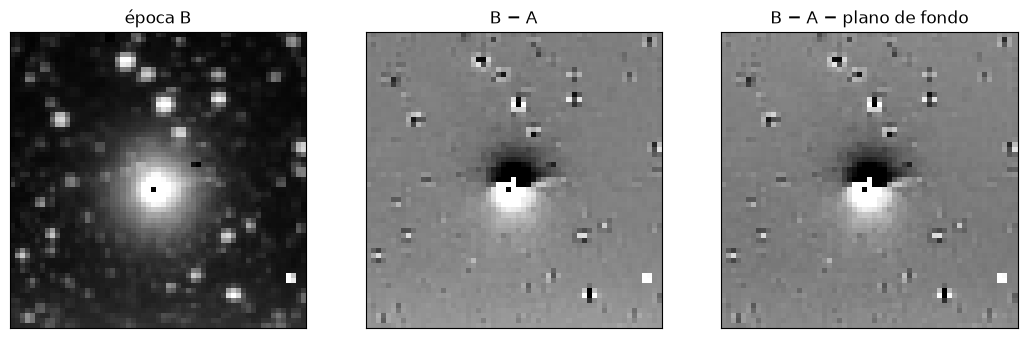

Barnard aparece como un par: blanco donde estaba en B, negro donde está en A (más al norte).


In [15]:
LO, HI = {1: (0.75, 1.09), 2: (1.10, 1.62), 3: (1.63, 2.41), 4: (2.42, 3.82), 5: (3.83, 4.41), 6: (4.42, 5.00)}[DET]

def subband(lam):
    return (lam - LO) / (HI - LO) * 17 - 0.5

def reference(frames, cur):
    best, best_score = None, math.inf
    for f in frames:
        if f is cur:
            continue
        dsub = abs(subband(f['lambda']) - subband(cur['lambda']))
        score = 0 if dsub <= 1 else dsub * 1000
        if f['season'] == cur['season']:
            score += 1e6
        score -= abs(f['mjd'] - cur['mjd'])
        if score < best_score:
            best, best_score = f, score
    return best

def subtract_plane(img, flags, sigma):
    n = img.shape[0]
    jj, ii = np.mgrid[0:n, 0:n]
    a, b, c = np.median(img[(flags & BAD_MASK) == 0]), 0.0, 0.0
    for _ in range(2):
        keep = ((flags & BAD_MASK) == 0) & (np.abs(img - (a + b * ii + c * jj)) < 3 * sigma)
        M = np.column_stack([np.ones(keep.sum()), ii[keep], jj[keep]])
        a, b, c = np.linalg.lstsq(M, img[keep], rcond=None)[0]
    return img - (a + b * ii + c * jj)

cur = frames[0]
refd = reference(frames, cur)
_, sig2 = stats(cur['image'], cur['flags'])
diff = cur['image'] - refd['image']
diff_flat = subtract_plane(diff, cur['flags'] | refd['flags'], sig2 * math.sqrt(2))
print(f"B = MJD {cur['mjd']:.1f} (λ {cur['lambda']:.3f} µm), A = MJD {refd['mjd']:.1f} (λ {refd['lambda']:.3f} µm), Δt = {refd['mjd'] - cur['mjd']:.0f} días")

gray = lambda d: np.clip(0.5 + 0.5 * np.arcsinh(d / sig2 / 2) / np.arcsinh(20), 0, 1)
fig, ax = plt.subplots(1, 3, figsize=(13, 4.3))
m, s = stats(cur['image'], cur['flags']); hi = max(percentile(cur['image'], cur['flags'], 0.998) - m, 30 * s)
ax[0].imshow(stretch(cur['image'], m, s, hi), cmap='gray'); ax[0].set_title('época B')
ax[1].imshow(gray(diff), cmap='gray', vmin=0, vmax=1); ax[1].set_title('B − A')
ax[2].imshow(gray(diff_flat), cmap='gray', vmin=0, vmax=1); ax[2].set_title('B − A − plano de fondo')
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.show()
print('Barnard aparece como un par: blanco donde estaba en B, negro donde está en A (más al norte).')

**Suma (apilado).** Media, píxel a píxel, de las imágenes desde la referencia hasta la actual, con dos cuidados:

- Cada imagen se lleva al mismo fondo antes de promediar.
- Se excluyen sus píxeles con banderas malas, salvo `NONLINEAR`, que conserva señal. Así los rayos cósmicos desaparecen del apilado.

El ruido baja como 1/√N.

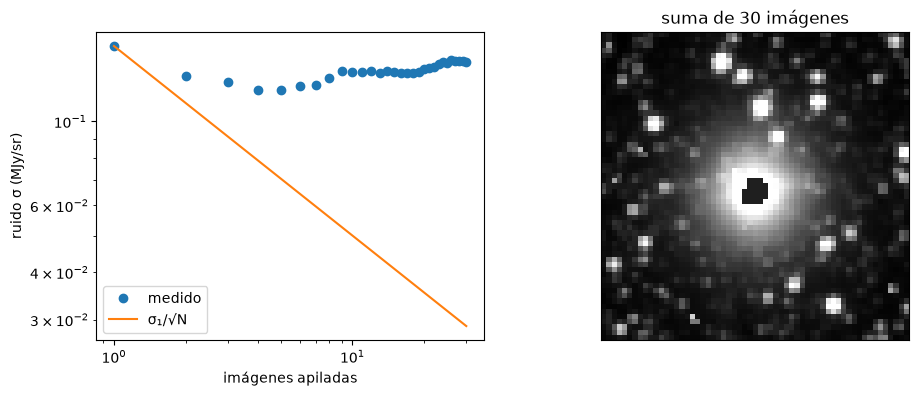

In [16]:
def stack(frames, ref_median):
    s = np.zeros_like(frames[0]['image']); n = np.zeros_like(s)
    for f in frames:
        good = ((f['flags'] & ~NONLINEAR) & BAD_MASK) == 0
        bg, _ = stats(f['image'], f['flags'])
        s[good] += f['image'][good] + (ref_median - bg)
        n[good] += 1
    return np.where(n > 0, s / np.maximum(n, 1), ref_median)

m0, s0 = stats(frames[0]['image'], frames[0]['flags'])
Ns, noise = [], []
for N in range(1, len(frames) + 1):
    st = stack(frames[:N], m0)
    Ns.append(N); noise.append(stats(st, np.zeros_like(frames[0]['flags']))[1])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].loglog(Ns, noise, 'o', label='medido'); ax[0].loglog(Ns, noise[0] / np.sqrt(Ns), '-', label='σ₁/√N')
ax[0].set_xlabel('imágenes apiladas'); ax[0].set_ylabel('ruido σ (MJy/sr)'); ax[0].legend()
ax[1].imshow(stretch(stack(frames, m0), m0, s0, 30 * s0), cmap='gray'); ax[1].set_title(f'suma de {len(frames)} imágenes')
ax[1].set_xticks([]); ax[1].set_yticks([])
plt.show()

## 9. Fotometría de apertura y espectro

*Código: `spherex/sky/phot.py` (`local_background`, `aperture`, `measure`).*

Se sigue la herramienta de descubrimiento de fuentes de SPHEREx (`aperture_photometry.py`):

1. **Fondo**: mediana recortada a 3σ (hasta 5 pasadas) de los píxeles buenos en un anillo de 7 a 16 píxeles.
2. **Flujo**: suma de `(valor − fondo)` en los píxeles con centro dentro de un radio de 3 píxeles. Los píxeles malos (salvo `NONLINEAR`) cuentan como fondo.
3. **Error**: raíz de la suma de `VARIANCE` en la apertura.
4. **Fiabilidad**: la medida es poco fiable si más del 30 % de la apertura está marcada, y se descarta si no queda ningún píxel bueno.
5. **Unidades**: la suma está en MJy/sr × píxeles; por el ángulo sólido del píxel (6.15″)² en sr y por 10⁹ queda en **mJy**, la unidad que usan las herramientas de IRSA.
6. **Longitud de onda**: la de la posición exacta de la fuente en esa imagen (WAVE-TAB), no la del centro del campo.

In [17]:
AP_R, ANN_IN, ANN_OUT = 3.0, 7.0, 16.0
FLUX_SCALE = (PIX / 3600 * DEG) ** 2 * 1e9            # MJy/sr·píxel → mJy

def local_background(img, flags, x, y, rin, rout):
    n = img.shape[0]; r = math.ceil(rout); vals = []
    for j in range(int(y) - r, int(y) + r + 1):
        for i in range(int(x) - r, int(x) + r + 1):
            if 0 <= i < n and 0 <= j < n and not flags[j, i] & BAD_MASK:
                if rin <= math.hypot(i + 0.5 - x, j + 0.5 - y) <= rout:
                    vals.append(img[j, i])
    vals = np.array(vals)
    for _ in range(5):
        med = np.median(vals); std = math.sqrt(np.mean((vals - med) ** 2))
        kept = vals[np.abs(vals - med) <= 3 * std]
        if len(kept) == len(vals) or len(kept) < 5:
            break
        vals = kept
    return np.median(vals)

def aperture(f, x, y):
    img, var, flags = f['image'], f['variance'], f['flags']
    n = img.shape[0]; bg = local_background(img, flags, x, y, ANN_IN, ANN_OUT)
    flux = variance = 0.0; npix = bad = 0
    r = math.ceil(AP_R)
    for j in range(int(y) - r, int(y) + r + 1):
        for i in range(int(x) - r, int(x) + r + 1):
            if math.hypot(i + 0.5 - x, j + 0.5 - y) > AP_R:
                continue
            npix += 1
            if not (0 <= i < n and 0 <= j < n) or (flags[j, i] & ~NONLINEAR) & BAD_MASK:
                bad += 1; continue
            flux += img[j, i] - bg; variance += var[j, i]
    return flux * FLUX_SCALE, math.sqrt(variance) * FLUX_SCALE, npix - bad, npix

Comparación con **photutils**, la librería que usa la herramienta de IRSA, sobre una estrella de campo brillante y no saturada. El paquete cuenta los píxeles cuyo centro cae en la apertura; photutils usa aquí el solapamiento exacto, así que se esperan diferencias de unos pocos por ciento.

In [18]:
f = frames[0]
img = f['image']; n = img.shape[0]
cand = img.copy(); cand[(f['flags'] & BAD_MASK) != 0] = -np.inf
# La estrella de campo más brillante sin banderas, lejos del borde y de Barnard.
order = np.argsort(cand, axis=None)[::-1]
bx, by = grid.to_pixel(*position(BARNARD, f['mjd']))
for k in order:
    sj, si = divmod(k, n)
    if 17 <= si < n - 17 and 17 <= sj < n - 17 and math.hypot(si - bx, sj - by) > 12:
        break
sx, sy = si + 0.5, sj + 0.5
flux, err, good, npix = aperture(f, sx, sy)
print(f'Estrella de campo en ({sx}, {sy}): {flux:.2f} ± {err:.2f} mJy ({good}/{npix} píxeles buenos)')

try:
    from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry, ApertureStats
    from astropy.stats import SigmaClip
    pos = (sx - 0.5, sy - 0.5)                         # photutils: centros de píxel en enteros
    ann = ApertureStats(img, CircularAnnulus(pos, ANN_IN, ANN_OUT), sigma_clip=SigmaClip(sigma=3, maxiters=5),
                        mask=(f['flags'] & BAD_MASK) != 0)
    ap = CircularAperture(pos, AP_R)
    s = aperture_photometry(img - ann.median, ap)['aperture_sum'][0] * FLUX_SCALE
    print(f'photutils (solapamiento exacto): {s:.2f} mJy → diferencia {100 * (flux - s) / s:+.1f} %')
except ImportError:
    print('photutils no está instalado; se omite la comparación.')

Estrella de campo en (33.5, 20.5): 34.75 ± 0.23 mJy (29/29 píxeles buenos)


photutils (solapamiento exacto): 34.50 mJy → diferencia +0.7 %


**Espectro.** Midiendo la misma fuente en todas las imágenes, cada una a su λ, se obtiene el espectro. Aquí, con la estrella de campo en el detector 2: cada punto es una visita.

30 medidas entre 1.090 y 1.664 µm


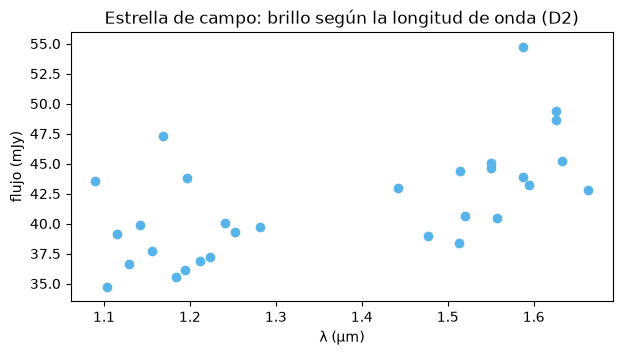

In [19]:
spec = []
star_ra, star_dec = grid.to_sky(sx, sy)
for f in frames:
    fl, er, gd, npx = aperture(f, sx, sy)
    if gd:                                             # sin ningún píxel bueno no hay medida
        spec.append((f['lambda_at'](star_ra, star_dec), fl, er))
spec = np.array(spec)
print(f'{len(spec)} medidas entre {spec[:, 0].min():.3f} y {spec[:, 0].max():.3f} µm')
plt.figure(figsize=(7, 3.5))
plt.errorbar(spec[:, 0], spec[:, 1], spec[:, 2], fmt='o', color='#56B4E9')
plt.xlabel('λ (µm)'); plt.ylabel('flujo (mJy)'); plt.title('Estrella de campo: brillo según la longitud de onda (D2)')
plt.show()

## 10. Centroide, seguimiento y movimiento propio

*Código: `spherex/sky/phot.py` (`centroid`, `track`, `Motion.fit`, `proper_motion`, `proper_motion_err`).*

- **Centroide**: media ponderada por `(valor − fondo)` positivo en un radio de 2 píxeles, con 4 iteraciones. Puede moverse como mucho `maxShift` píxeles respecto al punto de partida. El fondo sale de un anillo de 4.5 a 7.5 píxeles. Aquí **no** se excluyen los píxeles saturados: aunque estén marcados siguen indicando dónde está la estrella; solo se excluyen los que no tienen datos. La señal se mide como S/N = suma / (σ·√n).
- **Seguimiento**: desde la visita donde se hizo clic, hacia delante y hacia atrás en el tiempo, se refina el centroide partiendo del anterior (desplazamiento máximo 1.5 píxeles). Una visita cuenta como detección si S/N ≥ 5.
- **Ajuste**: recta `x(t) = x₀ + vₓ(t − t₀)` por mínimos cuadrados, y lo mismo en y. Si las detecciones abarcan menos de 60 días, se supone que la fuente no se mueve. Se descartan una vez los puntos a más de 0.6 píxeles de la recta y se vuelve a ajustar.
- **Errores**: `σ_v = rms(residuos, n−2) / √Σ(t − t₀)²`.
- **Movimiento propio**: `μα* = −vₓ · 6.15 · 365.25` y `μδ = −v_y · 6.15 · 365.25` en ″/año. El signo menos viene de que el este está a la izquierda y el norte arriba en la rejilla.
- **¿Se mueve?**: solo si la velocidad supera 0.2 píxeles/año y además es mayor que 3σ.

Barnard:   μα* = -4.60 ± 0.72, μδ = +9.08 ± 0.86 ″/año (21 detecciones)
           Gaia DR3: μα* = -0.80, μδ = +10.36 ″/año
Control (estrella de campo): μα* = +0.08 ± 0.10, μδ = -0.38 ± 0.14 ″/año, ¿se mueve? False


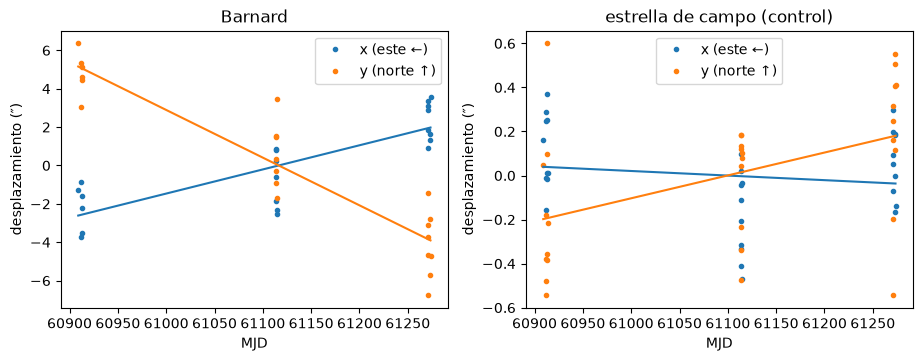

In [20]:
def centroid(f, x, y, max_shift):
    img, flags = f['image'], f['flags']; n = img.shape[0]
    _, sigma = stats(img, flags)
    bg = local_background(img, flags, x, y, 4.5, 7.5)
    cx, cy, snr = x, y, 0.0
    for _ in range(4):
        sw = sxw = syw = tot = 0.0; npix = 0
        for j in range(int(cy) - 2, int(cy) + 3):
            for i in range(int(cx) - 2, int(cx) + 3):
                if not (0 <= i < n and 0 <= j < n) or flags[j, i] & MISSING:
                    continue
                px, py = i + 0.5, j + 0.5
                if math.hypot(px - cx, py - cy) > 2:
                    continue
                v = img[j, i] - bg; tot += v; npix += 1
                if v > 0:
                    sw += v; sxw += v * px; syw += v * py
        if npix == 0 or sw == 0:
            return x, y, 0.0
        snr = tot / (sigma * math.sqrt(npix))
        nx, ny = sxw / sw, syw / sw
        d = math.hypot(nx - x, ny - y)
        if d > max_shift:
            nx, ny = x + (nx - x) * max_shift / d, y + (ny - y) * max_shift / d
        cx, cy = nx, ny
    return cx, cy, snr

def track(frames, start, x, y):
    pts = []
    for seq in (frames[start:], frames[:start][::-1]):
        gx, gy = x, y
        for f in seq:
            cx, cy, snr = centroid(f, gx, gy, 1.5)
            if snr >= 5:
                gx, gy = cx, cy
                pts.append((f['mjd'], cx, cy))
    return np.array(sorted(pts))

def fit(pts):
    t, x, y = pts[:, 0], pts[:, 1], pts[:, 2]
    t0 = t.mean(); dt = t - t0
    if t.max() - t.min() < 60:
        return dict(t0=t0, x0=x.mean(), y0=y.mean(), vx=0, vy=0, evx=0, evy=0, moving=False)
    stt = (dt ** 2).sum()
    vx, vy = (dt * (x - x.mean())).sum() / stt, (dt * (y - y.mean())).sum() / stt
    rx, ry = x - (x.mean() + vx * dt), y - (y.mean() + vy * dt)
    n = len(t)
    evx, evy = (math.sqrt((rx ** 2).sum() / (n - 2)) / math.sqrt(stt), math.sqrt((ry ** 2).sum() / (n - 2)) / math.sqrt(stt)) if n > 2 else (0, 0)
    speed = math.hypot(vx, vy)
    moving = speed * 365.25 > 0.2 and speed > 3 * math.hypot(evx, evy)
    return dict(t0=t0, x0=x.mean(), y0=y.mean(), vx=vx, vy=vy, evx=evx, evy=evy, moving=moving)

def motion(frames, x, y):
    pts = track(frames, 0, x, y)
    m = fit(pts)
    res = np.hypot(pts[:, 1] - (m['x0'] + m['vx'] * (pts[:, 0] - m['t0'])), pts[:, 2] - (m['y0'] + m['vy'] * (pts[:, 0] - m['t0'])))
    kept = pts[res < 0.6]
    if 2 <= len(kept) < len(pts):
        m = fit(kept); pts = kept
    k = PIX * 365.25
    m.update(pmra=-m['vx'] * k, pmdec=-m['vy'] * k, epmra=m['evx'] * k, epmdec=m['evy'] * k, pts=pts)
    return m

bx, by = grid.to_pixel(*position(BARNARD, frames[0]['mjd']))
mb = motion(frames, bx, by)
ms = motion(frames, sx, sy)
print(f"Barnard:   μα* = {mb['pmra']:+.2f} ± {mb['epmra']:.2f}, μδ = {mb['pmdec']:+.2f} ± {mb['epmdec']:.2f} ″/año ({len(mb['pts'])} detecciones)")
print(f"           Gaia DR3: μα* = {BARNARD['pmra'] / 1000:+.2f}, μδ = {BARNARD['pmdec'] / 1000:+.2f} ″/año")
print(f"Control (estrella de campo): μα* = {ms['pmra']:+.2f} ± {ms['epmra']:.2f}, μδ = {ms['pmdec']:+.2f} ± {ms['epmdec']:.2f} ″/año, ¿se mueve? {ms['moving']}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, m, name in ((ax[0], mb, 'Barnard'), (ax[1], ms, 'estrella de campo (control)')):
    t = m['pts'][:, 0]
    a.plot(t, (m['pts'][:, 1] - m['x0']) * PIX, 'o', ms=3, label='x (este ←)')
    a.plot(t, (m['pts'][:, 2] - m['y0']) * PIX, 'o', ms=3, label='y (norte ↑)')
    a.plot(t, m['vx'] * (t - m['t0']) * PIX, '-', color='C0'); a.plot(t, m['vy'] * (t - m['t0']) * PIX, '-', color='C1')
    a.set_title(name); a.set_xlabel('MJD'); a.set_ylabel('desplazamiento (″)'); a.legend()
plt.show()

En el detector 2, Barnard (J ≈ 5) satura: su núcleo queda marcado (`OVERFLOW`, `SUR_ERROR`, `BLOOM`…), y el centroide de un núcleo saturado se sesga según la orientación del detector, que cambia entre temporadas. Por eso la app muestra la incertidumbre, avisa de la saturación y compara con el catálogo dentro de 3σ más 0.3″/año de margen para errores sistemáticos. La estrella de control, sin saturar, debe dar un movimiento compatible con cero.

## 11. Gaia DR3 desde el CDN de la ESA

*Código: `spherex/gaia/healpix.py`, `ranges.py`, `store.py`.*

Gaia DR3 se publica como 3386 archivos `GaiaSource_AAAAAA-BBBBBB.csv.gz` de ~230 MB. Para usarlos sin descargarlo todo se aprovecha su organización espacial:

- `source_id` lleva en sus bits altos el píxel **HEALPix** (esquema anidado, nivel 12) de la fuente: `source_id >> 35`.
- Las filas van ordenadas por `source_id`, y el nombre del archivo es el rango de píxeles de **nivel 8** (~0.23°) que contiene. El nivel 8 de una fila es `source_id >> 43`.

### 11.1 HEALPix anidado

`ang2pix` en esquema anidado: se separan la región ecuatorial (|z| ≤ 2/3) y los casquetes polares, se obtiene la cara base (0–11) y las coordenadas (ix, iy) dentro de ella, y se intercalan sus bits.

In [21]:
def spread(v):
    out, i = 0, 0
    while v:
        out |= (v & 1) << (2 * i); v >>= 1; i += 1
    return out

def ang2pix(order, ra, dec):
    nside = 1 << order
    z = math.sin(dec * DEG); za = abs(z)
    tt = (ra / 90) % 4
    if za <= 2 / 3:
        t1 = nside * (0.5 + tt); t2 = nside * z * 0.75
        jp, jm = int(t1 - t2), int(t1 + t2)
        ifp, ifm = jp // nside, jm // nside
        face = (ifp | 4) if ifp == ifm else (ifp if ifp < ifm else ifm + 8)
        ix = jm & (nside - 1); iy = nside - (jp & (nside - 1)) - 1
    else:
        ntt = min(int(tt), 3); tp = tt - ntt
        tmp = nside * math.sqrt(3 * (1 - za))
        jp, jm = min(int(tp * tmp), nside - 1), min(int((1 - tp) * tmp), nside - 1)
        face, ix, iy = (ntt, nside - jm - 1, nside - jp - 1) if z >= 0 else (ntt + 8, jp, jm)
    return (face << (2 * order)) + spread(ix) + (spread(iy) << 1)

rng = np.random.default_rng(1)
test = [(rng.uniform(0, 360), math.degrees(math.asin(rng.uniform(-1, 1)))) for _ in range(20000)]
try:
    import hpgeom
    ref_pix = hpgeom.angle_to_pixel(2 ** 12, np.array([t[0] for t in test]), np.array([t[1] for t in test]), nest=True, lonlat=True)
    mine = np.array([ang2pix(12, ra, dec) for ra, dec in test])
    print(f'Comparado con hpgeom en {len(test)} puntos al azar: {np.sum(mine != ref_pix)} diferencias')
except ImportError:
    print('hpgeom no está instalado; se valida solo con source_id.')

rows_sid = list(csv.reader(open(ROOT / 'tests/data/healpix_rows.csv')))[1:]
miss = sum(ang2pix(12, float(ra), float(dec)) != int(sid) >> 35 for sid, ra, dec in rows_sid)
print(f'Contra source_id de Gaia: {len(rows_sid) - miss} de {len(rows_sid)} coinciden en nivel 12')
print('(Las pocas diferencias son fuentes junto al borde de un píxel o rápidas como Barnard: el source_id')
print(' se asignó con la posición que Gaia tenía al numerarlas, no con la de DR3.)')

pix_barnard = ang2pix(8, BARNARD['ra'], BARNARD['dec'])
print('\nPíxel de nivel 8 de Barnard:', pix_barnard, '| desde su source_id:', 4472832130942575872 >> 43)

Comparado con hpgeom en 20000 puntos al azar: 0 diferencias
Contra source_id de Gaia: 147 de 150 coinciden en nivel 12
(Las pocas diferencias son fuentes junto al borde de un píxel o rápidas como Barnard: el source_id
 se asignó con la posición que Gaia tenía al numerarlas, no con la de DR3.)

Píxel de nivel 8 de Barnard: 508502 | desde su source_id: 508502


**Píxeles de un campo.** El motor pide un cono de 0.15°. Los píxeles de nivel 8 que toca se obtienen muestreando el círculo con un paso de 0.05°, un cuarto del tamaño de píxel.

In [22]:
def disc_pixels(ra, dec, radius, step=0.05):
    seen = {ang2pix(8, ra, dec)}
    cosd = max(math.cos(dec * DEG), 1e-6)
    k = math.ceil(radius / step)
    for j in range(-k, k + 1):
        for i in range(-k, k + 1):
            dx, dy = i * step, j * step
            if math.hypot(dx, dy) <= radius + step:
                seen.add(ang2pix(8, ra + dx / cosd, max(-90, min(90, dec + dy))))
    return sorted(seen)

field_pixels = disc_pixels(RA, DEC, 0.15)
print('Píxeles de nivel 8 del campo de Barnard:', field_pixels)

Píxeles de nivel 8 del campo de Barnard: [508499, 508500, 508502, 508503, 508508]


### 11.2 Listado del CDN y archivo que contiene un píxel

El navegador de archivos del CDN lee un almacenamiento de tipo S3: `?prefix=…&delimiter=/` devuelve XML (`ListBucketResult`) paginado de 1000 en 1000 con `marker`. El proxy guarda el índice resultante en `gaia/index.json`.

In [23]:
LIST = 'https://gaia.eu-1.cdn77-storage.com/?prefix=Gaia/gdr3/gaia_source/&delimiter=/'
CDN = 'https://cdn.gea.esac.esa.int/Gaia/gdr3/gaia_source/'
GAIA_RE = re.compile(r'GaiaSource_(\d+)-(\d+)\.csv\.gz$')

def gaia_index():
    cached = Path.home() / '.cache/spherex-proxy/gaia/index.json'
    if cached.exists():
        return [(f['Name'], f['Lo'], f['Hi'], f['Size']) for f in json.loads(cached.read_text())], 'caché del proxy'
    files, marker = [], ''
    while True:
        root = ET.fromstring(http_get(LIST + (f'&marker={urllib.parse.quote(marker)}' if marker else ''), timeout=60))
        ns = {'s': root.tag.split('}')[0].strip('{')} if '}' in root.tag else {}
        q = (lambda p: 's:' + p) if ns else (lambda p: p)
        contents = root.findall(q('Contents'), ns)
        for c in contents:
            key = c.find(q('Key'), ns).text
            m = GAIA_RE.search(key)
            if m:
                files.append((key.split('/')[-1], int(m[1]), int(m[2]), int(c.find(q('Size'), ns).text)))
        if root.find(q('IsTruncated'), ns).text != 'true' or not contents:
            break
        marker = contents[-1].find(q('Key'), ns).text
    return sorted(files, key=lambda f: f[1]), 'CDN'

files, origin = gaia_index()
print(f'{len(files)} archivos ({origin}); {sum(f[3] for f in files) / 1e9:.0f} GB en total')
gfile = next(f for f in files if f[1] <= pix_barnard <= f[2])
print('Barnard está en', gfile[0], f'({gfile[3] / 1e6:.0f} MB, píxeles {gfile[1]}–{gfile[2]})')

3386 archivos (caché del proxy); 753 GB en total
Barnard está en GaiaSource_508501-508680.csv.gz (237 MB, píxeles 508501–508680)


### 11.3 Descarga por rangos en paralelo y descompresión en flujo

Un `.csv.gz` es un único flujo gzip: no se puede empezar a leer en mitad del archivo. Lo que sí se puede es **descargarlo más rápido**:

1. Se piden trozos con cabeceras `Range: bytes=a-b` (respuesta `206 Partial Content`), cada uno por una conexión distinta. El CDN limita la velocidad por conexión; `urllib` abre una conexión HTTP/1.1 nueva para cada petición, así que las peticiones en paralelo usan conexiones distintas.
2. Los trozos se entregan en orden a un descompresor que va leyendo las líneas.

Aquí se demuestra con los primeros 2 MiB del archivo, en dos rangos paralelos.

In [24]:
def get_range(url, lo, hi):
    req = urllib.request.Request(url, headers={'Range': f'bytes={lo}-{hi}', 'User-Agent': 'spherex-sky-timeline-notebook'})
    with urllib.request.urlopen(req, timeout=120) as r:
        assert r.status == 206, r.status
        return r.read()

CHUNK = 1 << 20
try:
    t0 = time.time()
    with ThreadPoolExecutor(2) as pool:
        parts = list(pool.map(lambda k: get_range(CDN + gfile[0], k * CHUNK, (k + 1) * CHUNK - 1), range(2)))
    print(f'2 rangos de 1 MiB en {time.time() - t0:.1f} s')
    d = zlib.decompressobj(wbits=31)                  # gzip
    text = b''.join(d.decompress(p) for p in parts).decode()
    lines = [l for l in text.split('\n')[:-1] if not l.startswith('#')]
    header = lines[0].split(',')
    col = {n: header.index(n) for n in ['source_id', 'ra', 'dec', 'parallax', 'pmra', 'pmdec', 'phot_g_mean_mag']}
    print(f'{len(header)} columnas; posiciones de las usadas: {col}')
    sids = [int(l.split(',')[col['source_id']]) for l in lines[1:]]
    pix8 = [s >> 43 for s in sids]
    print(f'{len(sids)} fuentes en estos 2 MiB; píxeles de nivel 8 del {min(pix8)} al {max(pix8)}; ordenadas: {pix8 == sorted(pix8)}')
except Exception as e:
    print('El CDN no respondió:', e)

2 rangos de 1 MiB en 1.8 s
152 columnas; posiciones de las usadas: {'source_id': 2, 'ra': 5, 'dec': 7, 'parallax': 9, 'pmra': 13, 'pmdec': 15, 'phot_g_mean_mag': 69}
4838 fuentes en estos 2 MiB; píxeles de nivel 8 del 508501 al 508502; ordenadas: True


### 11.4 Teselas en disco

Mientras se descomprime, cada vez que cambia el píxel de nivel 8 se escribe la tesela anterior: un binario little-endian de 40 bytes por fuente con `source_id` (int64), `ra` y `dec` (float64, J2016), y `parallax`, `pmra`, `pmdec` y `phot_g_mean_mag` (float32; `null` se guarda como NaN). La petición de la app se responde en cuanto han pasado sus píxeles, y el resto del archivo termina en segundo plano.

Si el proxy ya procesó la zona de Barnard, sus teselas están en la caché y se leen así:

In [25]:
TILE = np.dtype([('source_id', '<i8'), ('ra', '<f8'), ('dec', '<f8'), ('parallax', '<f4'),
                 ('pmra', '<f4'), ('pmdec', '<f4'), ('g', '<f4')])
tile_dir = Path.home() / '.cache/spherex-proxy/gaia/tiles'
tiles = [tile_dir / str(p // 1000) / f'{p}.bin' for p in field_pixels]
present = [t for t in tiles if t.exists()]
if present:
    stars = np.concatenate([np.fromfile(t, dtype=TILE) for t in present])
    print(f'{len(present)} teselas, {len(stars)} fuentes de Gaia')
    print(stars[stars['source_id'] == 4472832130942575872])
elif USE_PROXY:
    print('Teselas no disponibles; se pide el catálogo al proxy (puede tardar minutos la primera vez)')
    cat = json.loads(http_get(f'{PROXY}/api/catalog?ra={RA}&dec={DEC}', timeout=1200))
    stars = np.array([(int(s['name'].split()[-1]) if s['catalog'] == 'Gaia DR3' else 0, s['ra'], s['dec'], np.nan, s['pmra'], s['pmdec'], s['mag'])
                      for s in cat['sources']], dtype=TILE)
    print(len(stars), 'fuentes')
else:
    stars = np.zeros(0, dtype=TILE)
    print('Sin proxy ni teselas: se omite.')

5 teselas, 20776 fuentes de Gaia
[(4472832130942575872, 269.44850253, 4.73942005, 546.97595, -801.55096, 10362.395, 8.1939745)]


**La capa de catálogo.** Cada fuente se dibuja en su posición de Gaia (J2016) con una flecha hasta donde la lleva su movimiento propio en la fecha de la imagen. Si la flecha llega a lo que se ve, el movimiento queda confirmado.

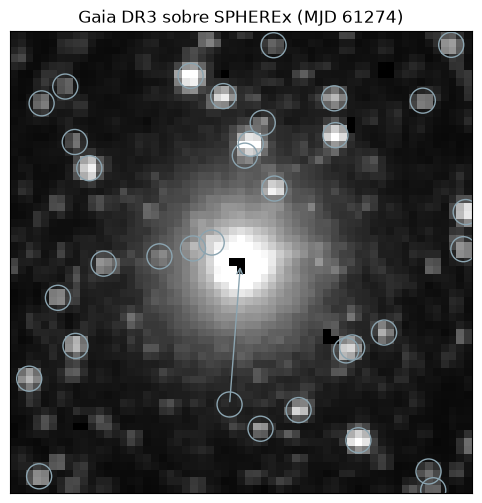

In [26]:
if len(stars):
    f = frames[-1]
    m, s = stats(f['image'], f['flags']); hi = max(percentile(f['image'], f['flags'], 0.998) - m, 30 * s)
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(stretch(f['image'], m, s, hi), cmap='gray')
    sel = stars[(stars['g'] < 16) | (np.hypot(stars['pmra'], stars['pmdec']) > 100)]
    for st in sel:
        src = dict(ra=st['ra'], dec=st['dec'], pmra=np.nan_to_num(st['pmra']), pmdec=np.nan_to_num(st['pmdec']), mjd=GAIA_EPOCH)
        x0, y0 = grid.to_pixel(st['ra'], st['dec'])
        x1, y1 = grid.to_pixel(*position(src, f['mjd']))
        x0, y0, x1, y1 = x0 - 0.5, y0 - 0.5, x1 - 0.5, y1 - 0.5   # imshow: centros de píxel en enteros
        if 0 <= x1 < grid.n and 0 <= y1 < grid.n:
            ax.add_patch(plt.Circle((x0, y0), 1.6, fill=False, color='#8ba4b0'))
            if math.hypot(x1 - x0, y1 - y0) > 0.25:
                ax.annotate('', (x1, y1), (x0, y0), arrowprops=dict(arrowstyle='->', color='#8ba4b0'))
    ax.set_title(f"Gaia DR3 sobre SPHEREx (MJD {f['mjd']:.0f})"); ax.set_xticks([]); ax.set_yticks([])
    plt.show()

## 12. CatWISE2020 y fusión de catálogos

*Código: `spherex/irsa/client.py` (`catwise`, `merge`, `_duplicate`).*

Gaia no ve las enanas marrones frías como WISE 0855; CatWISE2020 (en IRSA, por TAP) sí, con movimientos propios medidos en el infrarrojo. Hay tres detalles:

- **Unidades**: CatWISE da `pmra` y `pmdec` en ″/año; se pasan a mas/año.
- **Época**: sus posiciones están referidas a MJD 57170 (2015.4).
- **Fusión**:
  - Una entrada de CatWISE se descarta si, llevadas ambas a la misma época, está a menos de 3″ de una fuente de Gaia.
  - Los objetos rápidos aparecen a veces repetidos en CatWISE; se agrupan a menos de 6″ y se queda la entrada más brillante en W2.

In [27]:
CATWISE_EPOCH = 57170.0
W0855 = (133.758, -7.242)
adql = (f"SELECT source_name, ra, dec, pmra, pmdec, w2mpro FROM catwise_2020 "
        f"WHERE 1 = CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', {W0855[0]}, {W0855[1]}, 0.05)) "
        f"AND (w1mpro < 15.5 OR w2mpro < 16.5)")
try:
    t0 = time.time()
    body = http_get(f"{IRSA}/TAP/sync?" + urllib.parse.urlencode({'LANG': 'ADQL', 'FORMAT': 'csv', 'QUERY': adql}), timeout=300)
    cw_rows = list(csv.reader(io.StringIO(body.decode())))[1:]
    print(f'TAP CatWISE: {len(cw_rows)} fuentes en {time.time() - t0:.0f} s')
except Exception as e:
    print('TAP no respondió; se usan filas reales guardadas de una consulta anterior:', e)
    cw_rows = [['J085507.96-071439.3', '133.7831722', '-7.2442516', '-8.02120', '1.03570', '15.787'],
               ['J085508.34-071439.2', '133.7847613', '-7.2442498', '-7.96500', '0.80620', '15.721'],
               ['J085506.91-071437.5', '133.7788255', '-7.2437546', '-7.91990', '0.49390', '15.541'],
               ['J085509.69-071632.2', '133.7903927', '-7.2756254', '0.00963', '-0.00962', '17.668']]

catwise = [dict(name='CatWISE ' + r[0], ra=float(r[1]), dec=float(r[2]), pmra=1000 * float(r[3]), pmdec=1000 * float(r[4]),
                mjd=CATWISE_EPOCH, mag=float(r[5])) for r in cw_rows]

def merge(gaia, catwise):
    out = list(gaia)
    for e in sorted(catwise, key=lambda e: e['mag']):
        dup = False
        for i, o in enumerate(out):
            ra, dec = position(o, e['mjd'])
            sep = SkyCoord(ra, dec, unit='deg').separation(SkyCoord(e['ra'], e['dec'], unit='deg')).arcsec
            if sep < (3 if i < len(gaia) else 6):
                dup = True; break
        if not dup:
            out.append(e)
    return out

merged = merge([], catwise)
fast = [e for e in merged if math.hypot(e['pmra'], e['pmdec']) > 1000]
for e in fast:
    print(f"{e['name']}: μ = ({e['pmra']:.0f}, {e['pmdec']:.0f}) mas/año, W2 = {e['mag']}")
print(f'{len(catwise)} entradas de CatWISE → {len(merged)} tras agrupar duplicados')
a, b = fast
sep = SkyCoord(a['ra'], a['dec'], unit='deg').separation(SkyCoord(b['ra'], b['dec'], unit='deg')).arcsec
print(f'Las dos entradas rápidas que quedan son el mismo objeto, partido en varias detecciones por su')
print(f'movimiento; están a {sep:.0f}″, más que el límite de 6″ del agrupado, así que la app muestra ambas.')

TAP no respondió; se usan filas reales guardadas de una consulta anterior: The read operation timed out
CatWISE J085506.91-071437.5: μ = (-7920, 494) mas/año, W2 = 15.541
CatWISE J085508.34-071439.2: μ = (-7965, 806) mas/año, W2 = 15.721
4 entradas de CatWISE → 3 tras agrupar duplicados
Las dos entradas rápidas que quedan son el mismo objeto, partido en varias detecciones por su
movimiento; están a 21″, más que el límite de 6″ del agrupado, así que la app muestra ambas.


## 13. La simulación

*Código: `spherex/sky/field.py` (`schedule`, `field_stars`, `load_simulated`, `add_psfs`), `spherex/sky/source.py`.*

Sin proxy, la app usa una simulación que imita la estructura real, para que el resto del código sea el mismo:

- **Calendario**: un punto del cielo se observa cuando el Sol está a ~90° en longitud eclíptica, dos veces al año. Cerca de los polos eclípticos se observa casi continuamente. En cada pasada hay 17 o más visitas y cada una ve una de las 17 sub-bandas del filtro.
- **Brillo de cada fuente**: un cuerpo negro (`B_ν ∝ 1/(λ³(e^{hc/λkT} − 1))`) con bandas de absorción gaussianas (H₂O, CH₄, CO en las enanas marrones), más una variabilidad periódica (tipo Mira) o irregular (estrella joven).
- **Imagen**: cada fuente se dibuja como una PSF gaussiana **integrada en cada píxel** con la función de error, para que los desplazamientos de fracción de píxel se vean bien. Luego se añaden fondo zodiacal con gradiente, ruido, píxeles calientes y rayos cósmicos, con los mismos bits de banderas que los datos reales.

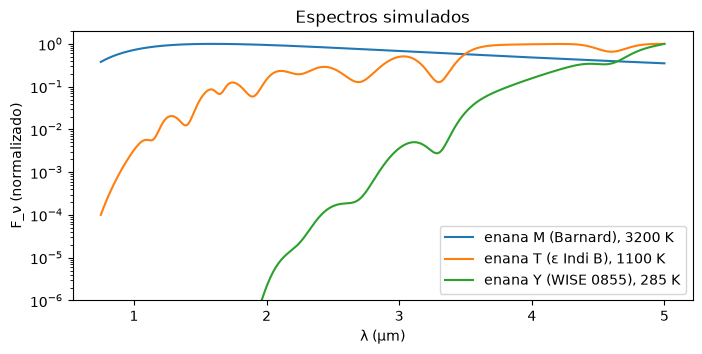

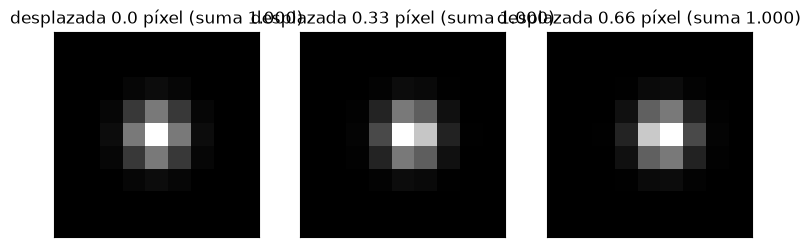

In [28]:
from scipy.special import erf

def planck_nu(lam, T):
    x = 14387.77 / (lam * T)
    return np.where(x > 700, 0, 1 / (lam ** 3 * np.expm1(np.minimum(x, 700))))

def absorb(f, lam, bands):
    for c, w, d in bands:
        f = f * (1 - d * np.exp(-0.5 * ((lam - c) / w) ** 2))
    return f

BD_BANDS = [(1.15, .05, .5), (1.4, .08, .75), (1.65, .04, .45), (1.9, .10, .75), (2.25, .12, .5), (2.7, .20, .8), (3.3, .15, .85), (4.6, .12, .35)]
lam = np.linspace(0.75, 5, 400)
plt.figure(figsize=(8, 3.5))
for T, name, bands in ((3200, 'enana M (Barnard)', []), (1100, 'enana T (ε Indi B)', BD_BANDS), (285, 'enana Y (WISE 0855)', BD_BANDS)):
    s = absorb(planck_nu(lam, T), lam, bands)
    plt.semilogy(lam, s / s.max(), label=f'{name}, {T} K')
plt.ylim(1e-6, 2); plt.xlabel('λ (µm)'); plt.ylabel('F_ν (normalizado)'); plt.legend(); plt.title('Espectros simulados')
plt.show()

def add_psf(img, x, y, sigma, flux):
    n = img.shape[0]; r = int(math.ceil(4 * sigma)) + 1
    x0, y0 = int(math.floor(x)) - r, int(math.floor(y)) - r
    k = 1 / (math.sqrt(2) * sigma)
    ex = 0.5 * (erf((np.arange(x0 + 1, x0 + 2 * r + 2) - x) * k) - erf((np.arange(x0, x0 + 2 * r + 1) - x) * k))
    ey = 0.5 * (erf((np.arange(y0 + 1, y0 + 2 * r + 2) - y) * k) - erf((np.arange(y0, y0 + 2 * r + 1) - y) * k))
    for j, wy in enumerate(ey):
        for i, wx in enumerate(ex):
            if 0 <= x0 + i < n and 0 <= y0 + j < n:
                img[y0 + j, x0 + i] += flux * wx * wy

fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, dx in zip(ax, (0.0, 0.33, 0.66)):
    im = np.zeros((9, 9)); add_psf(im, 4.5 + dx, 4.5, 1.8 / 2.3548, 1.0)
    a.imshow(im, cmap='gray'); a.set_title(f'desplazada {dx} píxel (suma {im.sum():.3f})'); a.set_xticks([]); a.set_yticks([])
plt.show()

## 14. Caché y claves

*Código: `spherex/irsa/cache.py`, `spherex/proxy.py` (`round_position`, `visits_data`, `catalog_data`), `spherex/engine/app.py` (`open`).*

- **Claves**: cada respuesta se guarda en disco bajo `sha256(clave)`, en una subcarpeta con sus dos primeros caracteres. La clave de un recorte incluye la ruta del archivo, el centro y el tamaño.
- **Redondeo**: WISE 0855 se mueve 8″/año, es decir 0.022″/día, y el sexto decimal del centro en grados son 0.0036″: sin redondear, su posición "actual" cambia la clave de cada recorte cada ~4 horas, y casi nunca coincidiría con las que dejó el precalentamiento del proxy. Redondeando a 0.0005° (1.8″), la clave dura de media unas 11 semanas; cambia antes si la posición cruza un borde de redondeo, como ocurre aquí a los 30 días.

In [29]:
def cache_path(key):
    h = hashlib.sha256(key.encode()).hexdigest()
    return f'{h[:2]}/{h}'

W0855_SRC = dict(ra=133.81890825, dec=-7.24704800, pmra=-8123.7, pmdec=673.2, mjd=51544.5)
now = 61358.5
for minutes in (0, 60, 60 * 6, 60 * 24, 60 * 24 * 30):
    ra, dec = position(W0855_SRC, now + minutes / 1440)
    raw_key = f'cutout {visits[0]["path"]} {ra:.6f} {dec:.6f} {SIZE:.5f}'
    rra, rdec = round_pos(ra, dec)
    rounded_key = f'cutout {visits[0]["path"]} {rra:.6f} {rdec:.6f} {SIZE:.5f}'
    print(f'+{minutes:6d} min  sin redondear → {cache_path(raw_key)[:14]}…   redondeado → {cache_path(rounded_key)[:14]}…')

+     0 min  sin redondear → 1f/1f948b04d41…   redondeado → 38/384a520c657…
+    60 min  sin redondear → 1f/1f948b04d41…   redondeado → 38/384a520c657…
+   360 min  sin redondear → 81/81d8c54c262…   redondeado → 38/384a520c657…
+  1440 min  sin redondear → 1c/1cdf5748c29…   redondeado → 38/384a520c657…
+ 43200 min  sin redondear → 3f/3f0fb90d776…   redondeado → f8/f863e0bef16…


## Resumen

| Operación | Código | Comprobado contra |
|---|---|---|
| Lista de imágenes por SIA y deduplicación | `irsa.VisitsSIA`, `visitsFromRows` | respuesta real de IRSA |
| Quitar la PSF del FITS | `fits.Parse`, `Join` | astropy lee el resultado |
| Píxel ↔ cielo TAN-SIP | `wcs.Celestial` | astropy, < 10⁻⁶″ |
| λ por píxel | `wcs.Wave` | astropy, < 10⁻⁶ µm |
| Banderas | `sky.BadMask` | nombres de la cabecera |
| Reproyección | `sky.LoadCutout` | posición de Gaia propagada |
| Diferencia, suma | `engine/compose.py`, `subtract_plane` | ruido ∝ 1/√N |
| Fotometría | `sky.Aperture` | photutils |
| Movimiento propio | `sky.Track`, `fit` | Gaia DR3 y estrella de control |
| HEALPix | `gaia.Ang2Pix` | hpgeom y `source_id` de Gaia |
| Gaia por rangos y teselas | `gaia.Store` | orden de las filas, teselas del proxy |
| CatWISE y fusión | `irsa.CatWISE`, `Merge` | WISE 0855 |